In [1]:
import pandas as pd
import tensorflow as tf
from matplotlib import pyplot as plt
import numpy as np

# Гречишкин Денис, ПМ-41
## Лабораторная работа №1
## Нейронные сети

## Цель работы: получить начальные знания о библиотеке Keras на примере простейших моделей персептронов.

## Часть 1. Модель из одного нейрона для линейной регрессии

## 1.1. Построение модели

In [2]:
def build_model(rate):
    # Строим модель в виде последовательно подключаемых
    # слоев (промежуточные слои соединяются автоматом).
    model = tf.keras.models.Sequential()

    # В нашем случае в виде одного слоя из
    # одного единственного нейрона:
    model.add(tf.keras.layers.Dense(units = 1, input_shape = (1, )))

    # Скомпилируем нашу модель в код, который исполнит
    # TensorFlow. В качестве функции потерь, которую
    # мы будем минимизировать, выберем среднеквадратическую ошибку
    model.compile(optimizer = tf.keras.optimizers.RMSprop(learning_rate = rate), loss = "mean_squared_error", metrics = [tf.keras.metrics.RootMeanSquaredError()])
    return model

    #функция для обучения модели на эталонных данных
def train_model(model, feature, label, epochs, batch_size):
    history = model.fit(x = feature, y = label, batch_size = batch_size, epochs = epochs)
    trained_weight = model.get_weights()[0]
    trained_bias = model.get_weights()[1]
    epochs = history.epoch
    hist = pd.DataFrame(history.history)
    rmse = hist["root_mean_squared_error"]
    return trained_weight, trained_bias, epochs, rmse

## 1.2. Визуализация результатов обучения.

In [3]:
def plot_the_model(trained_weight, trained_bias, feature, label):
    plt.xlabel("feature")
    plt.ylabel("label")
    plt.scatter(feature, label)

    # Модель линейной регрессии будет представлена красной линией
    # с началом в (x0, y0) и концом в (x1, y1).
    x0 = 0
    y0 = trained_bias
    x1 = feature[-1]
    y1 = trained_bias + (trained_weight*x1)
    plt.plot([x0, x1], [float(y0), float(y1)], c = 'r')
    plt.show()

def plot_the_loss_curve(epochs, rmse):
    plt.figure()
    plt.xlabel('epoch')
    plt.ylabel('epoch')
    plt.plot(epochs, rmse, label = 'Loss')
    plt.legend()
    plt.ylim([rmse.min()*0.97, rmse.max()])
    plt.grid()
    plt.show()

## 1.3. Подготовка датасета и обучение.

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step - loss: 564.4206 - root_mean_squared_error: 23.7575
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 552.0940 - root_mean_squared_error: 23.4967
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 543.2830 - root_mean_squared_error: 23.3084
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 535.9832 - root_mean_squared_error: 23.1513
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 529.5599 - root_mean_squared_error: 23.0122
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 523.7191 - root_mean_squared_error: 22.8849
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 518.2974 - root_mean_squared_error: 22.7661
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 513.1927 - root_mean_squared_error: 22.6538
Epoch 9/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 508.3374 - root_mean_squared_error: 22.5463
Epoch 10/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - loss: 503.6834 - root_mean_squared_error: 22.442

/tmp/ipykernel_21031/1845667112.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot([x0, x1], [float(y0), float(y1)], c = 'r')


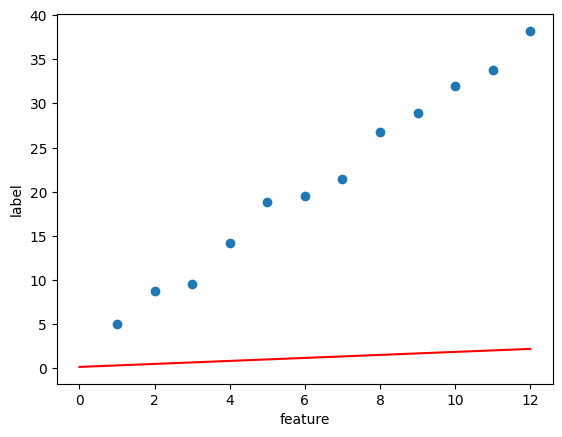

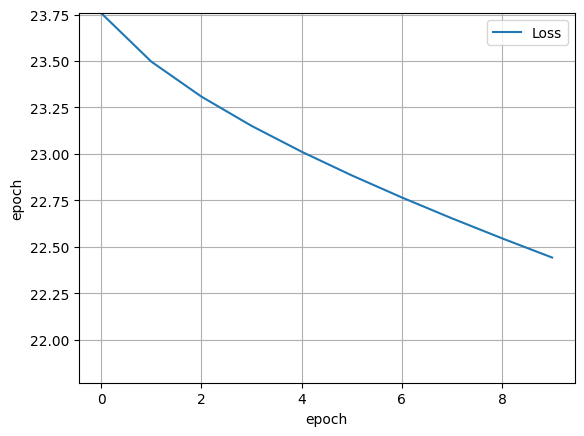

In [4]:
features = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0])
labels = np.array([5.0, 8.8, 9.6, 14.2, 18.8, 19.5, 21.4, 26.8, 28.9, 32.0, 33.8, 38.2])

learning_rate = 0.01
nepochs = 10
my_batch_size = 12
my_model = build_model(learning_rate)
trained_weight, trained_bias, epochs, rmse = train_model(my_model, features, labels, nepochs, my_batch_size)
print(epochs)
Rmse = np.array([rmse[i] for i in range(10)])
print(Rmse)
plot_the_model(trained_weight, trained_bias, features, labels)
plot_the_loss_curve(epochs, Rmse)

## Задание 1: Подобрать оптимальные параметры для обучения модели

оптимальные параметры:

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 525ms/step - loss: 281.9545 - root_mean_squared_error: 16.7915
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 201.2271 - root_mean_squared_error: 14.1855
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 155.1038 - root_mean_squared_error: 12.4541
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 123.0097 - root_mean_squared_error: 11.0910
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 98.8892 - root_mean_squared_error: 9.9443
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 80.0253 - root_mean_squared_error: 8.9457
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - loss: 64.9294 - root_mean_squared_error: 8.0579
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 52.6823 - root_mean_squared_error: 7.2583
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - loss: 42.6674 - root_mean_squared_error: 6.5320
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 34.4458 - root_mean_squared_er

/tmp/ipykernel_21031/1845667112.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot([x0, x1], [float(y0), float(y1)], c = 'r')


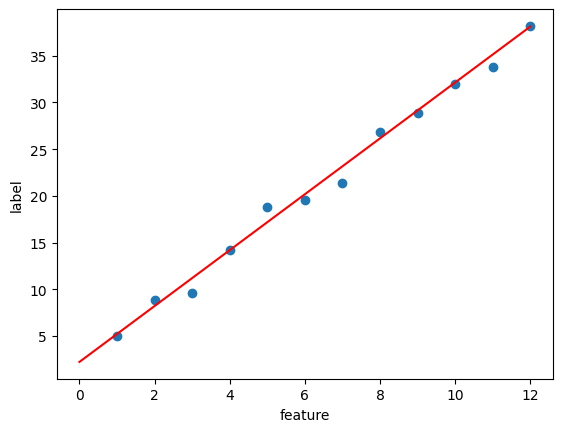

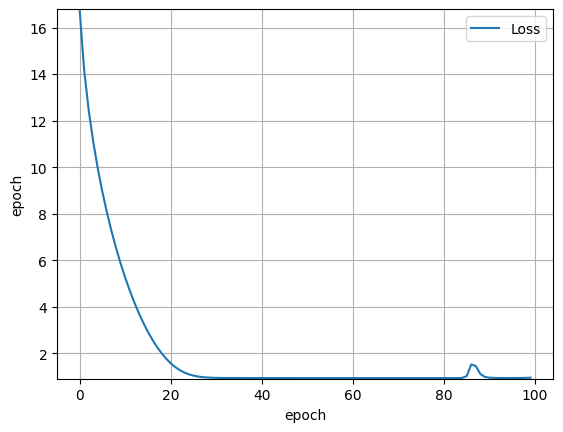

In [5]:
features = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0])
labels = np.array([5.0, 8.8, 9.6, 14.2, 18.8, 19.5, 21.4, 26.8, 28.9, 32.0, 33.8, 38.2])

learning_rate = 0.1
epochs = 100
my_batch_size = 12
my_model = build_model(learning_rate)
trained_weight, trained_bias, epochs, rmse = train_model(my_model, features, labels, epochs, my_batch_size)
Rmse = np.array([rmse[i] for i in range(100)])
plot_the_model(trained_weight, trained_bias, features, labels)
plot_the_loss_curve(epochs, Rmse)

слишком большая скорость обучения - быстро наступают стадии переобучения

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - loss: 1016.2759 - root_mean_squared_error: 31.8791
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 354.9828 - root_mean_squared_error: 18.8410
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 143.2318 - root_mean_squared_error: 11.9679
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 58.7107 - root_mean_squared_error: 7.6623
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 23.8234 - root_mean_squared_error: 4.8809
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 9.7460 - root_mean_squared_error: 3.1219
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 4.3318 - root_mean_squared_error: 2.0813
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 2.3727 - root_mean_squared_error: 1.5404
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 1.7085 - root_mean_squared_error: 1.3071
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 1.4943 - root_mean_squared_error: 1.2

/tmp/ipykernel_21031/1845667112.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot([x0, x1], [float(y0), float(y1)], c = 'r')


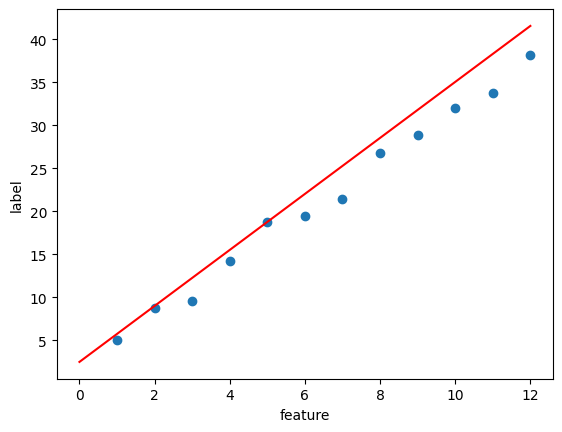

[31.87908173 18.84098625 11.96794891  7.66228819  4.88092566  3.12186527
  2.08128905  1.54035497  1.30708492  1.22243488  1.19322002  1.18095946
  1.17309332  1.16612101  1.15919268  1.15213192  1.14491439  1.13754416
  1.13003099  1.12238777  1.11462915  1.10677135  1.09883237  1.090832
  1.08279145  1.07473516  1.06668723  1.05867589  1.05072665  1.0428704
  1.03513622  1.02755427  1.02015591  1.01296878  1.00602436  0.99934983
  0.99296999  0.98690975  0.98118949  0.97582608  0.97083366  0.96622056
  0.96199268  0.95815003  0.95468861  0.95159984  0.9488709   0.94648516
  0.94442767  0.94272006  0.94180405  0.9471935   1.02995801  1.86449623
  5.39174175  6.23326111  3.5232923   1.95327544  1.33241892  1.10848927
  1.02645564  0.99466223  0.98303318  0.98225564  0.99129003  1.01541698
  1.07064676  1.19693792  1.48209596  2.06985736  3.03011322  3.91477966
  3.88327932  3.13981438  2.39511347  1.89606965  1.61009538  1.46309698
  1.40482354  1.41221392  1.48289907  1.63012254  1.87

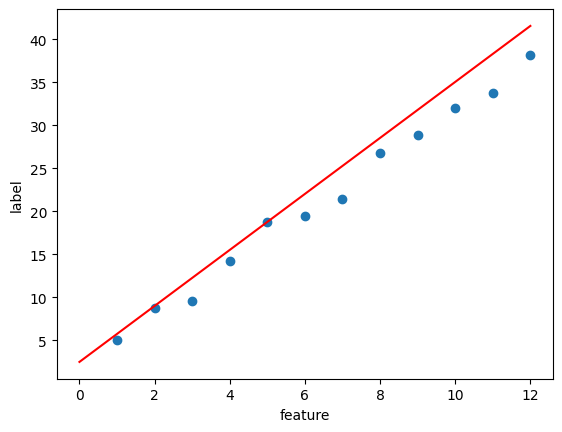

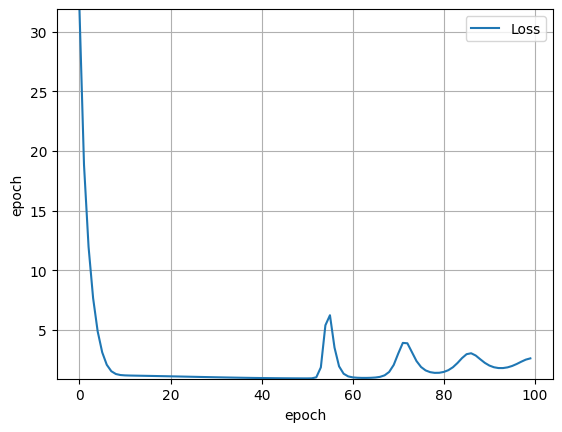

In [6]:
features = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0])
labels = np.array([5.0, 8.8, 9.6, 14.2, 18.8, 19.5, 21.4, 26.8, 28.9, 32.0, 33.8, 38.2])

learning_rate = 0.5
nepochs = 100
my_batch_size = 12
my_model = build_model(learning_rate)
trained_weight, trained_bias, epochs, rmse = train_model(my_model, features, labels, nepochs, my_batch_size)
plot_the_model(trained_weight, trained_bias, features, labels)
Rmse = np.array([rmse[i] for i in range(100)])
print(Rmse)
plot_the_model(trained_weight, trained_bias, features, labels)
plot_the_loss_curve(epochs, Rmse)

увеличиваем количество эпох - обучение длится дольше

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 552ms/step - loss: 1174.4318 - root_mean_squared_error: 34.2700
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 1002.4310 - root_mean_squared_error: 31.6612
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 890.5108 - root_mean_squared_error: 29.8414
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 804.0496 - root_mean_squared_error: 28.3558
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 732.4335 - root_mean_squared_error: 27.0635
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 670.8209 - root_mean_squared_error: 25.9002
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 616.5428 - root_mean_squared_error: 24.8303
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 567.9521 - root_mean_squared_error: 23.8317
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - loss: 523.9515 - root_mean_squared_error: 22.8900
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 483.7692 - root_mean

/tmp/ipykernel_21031/1845667112.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot([x0, x1], [float(y0), float(y1)], c = 'r')


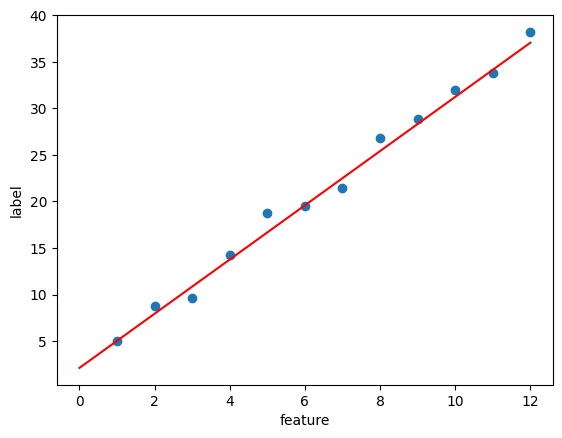

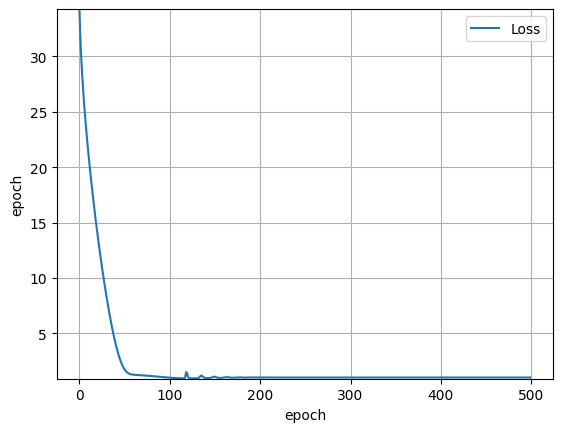

In [7]:
features = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0])
labels = np.array([5.0, 8.8, 9.6, 14.2, 18.8, 19.5, 21.4, 26.8, 28.9, 32.0, 33.8, 38.2])

learning_rate = 0.1
epochs = 500
my_batch_size = 12
my_model = build_model(learning_rate)
trained_weight, trained_bias, epochs, rmse = train_model(my_model, features, labels, epochs, my_batch_size)
plot_the_model(trained_weight, trained_bias, features, labels)
plot_the_loss_curve(epochs, rmse)

# 2. Модель многослойного персептрона

## **Задание 2:** Выбрать на двумерном пространстве несколько областей, разграниченнных прямыми линиями. Например, внутренняя или внешняя часть треугольника (квадрата, пятиугольника), либо некоторое количество полубесконечных секторов. Выбрать эталонные данные, которые будут отнесены к каждому из ваших классов. Перекодировать их номера в позиционные коды с помощью функции to_categorical.

In [8]:
def to_categorical(x, y):
    class_id = 0
    if(y < 0.0):
        class_id = 3
    else:
        if(x < 0):
            if(y < x + 10.0):
                class_id = 0
            else:
                class_id = 2
        else:
            if(y < -x + 10.0):
                class_id = 1
            else:
                class_id = 2
    return class_id

## **Задание 3**: Подготовить модель для обучения на выбранных данных. Для входного слоя число входов должно соотвествовать числу признаков (в нашемслучае их 2), а число нейронов минимальному числу линий, которые необходимы для разграничения ваших классов на плоскости. В качестве активационной функции использовать любую нелинейную (например relu). Для выходного слоя использовать активацию softmax. Провести обучение и проверить, что модель адекватно предсказывает принадлежность произвольных точек плоскости (не из набора для обучения). Визуализировать эти предсказания с помощью разноцветных маркеров на плоскости (цвет марекера = номер класса)

Epoch 1/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5034 - root_mean_squared_error: 0.2657
Epoch 2/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2608 - root_mean_squared_error: 0.1932
Epoch 3/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1713 - root_mean_squared_error: 0.1547
Epoch 4/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1290 - root_mean_squared_error: 0.1327
Epoch 5/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.1048 - root_mean_squared_error: 0.1192
Epoch 6/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0890 - root_mean_squared_error: 0.1093
Epoch 7/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0765 - root_mean_squared_error: 0.1013
Epoch 8/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0690 - root_mean_squared_error: 0.0961
Epoch 9/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0613 - root_mean_squared_error: 0.0903
Epoch 10/50
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0555 - r

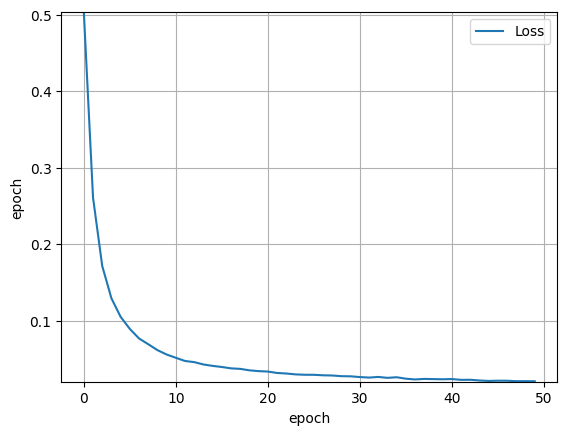

In [9]:
training_size = 10000
base_range = np.random.default_rng()
tr_features_x = -10 + 20*base_range.random(size = training_size)
tr_features_y = -10 + 20*base_range.random(size = training_size)
tr_classes = [to_categorical(x,y) for x,y in zip(tr_features_x, tr_features_y)]

tr_labels = tf.keras.utils.to_categorical(tr_classes, num_classes=4)

def build_model(rate):
    # Строим модель в виде последовательно подключаемых
    # слоев (промежуточные слои соединяются автоматом).
    model = tf.keras.models.Sequential()

    model.add(tf.keras.layers.Dense(units=16, input_shape=(2,), activation='relu'))
    model.add(tf.keras.layers.Dense(units=8, activation='relu'))
    model.add(tf.keras.layers.Dense(units=4, activation='softmax'))

    # Скомпилируем нашу модель в код, который исполнит
    # TensorFlow. В качестве функции потерь, которую
    # мы будем минимизировать, выберем среднеквадратическую ошибку
    loss = tf.keras.losses.CategoricalCrossentropy()
    model.compile(optimizer = tf.keras.optimizers.RMSprop(learning_rate = rate), loss = loss, metrics = [tf.keras.metrics.RootMeanSquaredError()])
    return model

#функция для обучения модели на эталонных данных
def train_model(model, feature, label, epochs, batch_size):
    history = model.fit(x = feature, y = label, batch_size = batch_size, epochs = epochs)
    epochs = history.epoch
    hist = pd.DataFrame(history.history)
    loss = hist["loss"]
    return epochs, loss


tr_features = np.array([tr_features_x, tr_features_y]).T

learn_rate = 0.001
n_epochs = 50
my_model = build_model(learn_rate)
my_batch_size = 10
epochs, rmse = train_model(model = my_model,
                            feature = tr_features,
                            label = tr_labels,
                            epochs = n_epochs,
                            batch_size = my_batch_size)
Rmse = np.array([rmse[i] for i in range(50)])
plot_the_loss_curve(epochs, Rmse)

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step


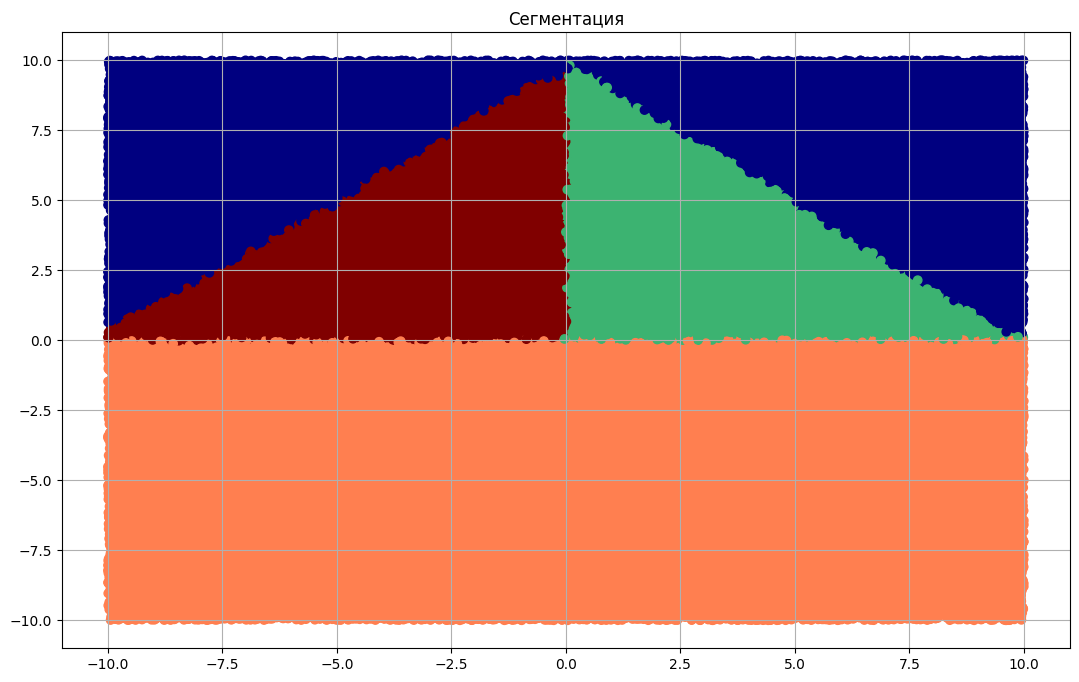

In [10]:
size = 100000
base_range = np.random.default_rng()
features_x = -10 + 20*base_range.random(size = size)
features_y = -10 + 20*base_range.random(size = size)
features = np.array([features_x, features_y]).T
classes = [to_categorical(x,y) for x,y in zip(features_x, features_y)]
labels = tf.keras.utils.to_categorical(classes, num_classes=None)
predictions = np.round(my_model.predict(features))
predicted_classes = [prediction for prediction in np.argmax(predictions, -1)]

colors = ['maroon', 'mediumseagreen', 'navy', 'coral']
fig = plt.figure(figsize = (10, 7))
fig.set_size_inches((13, 8))
ax = fig.add_subplot()
ax.set_title('Сегментация')
ax.grid(True)
ax.scatter(features_x, features_y, c=[colors[class_id] for class_id in predicted_classes])

## **Задание 4**: Искуственно увеличить число нейронов во входном слоев несколько раз, а также число эпох для обучения модели. Часть обучающей выборки выделите для кроссвалидации. Это проще всего сделать, подав функции model.fit параметр validation_split = 0.2 (тогда 20 процентов из обучающей выборки будет использоваться только для валидации). Провести обучение и проверить, что модель переобучилась. Визуализировать наступление переобучения с помощью кривых для функции потерь, а также с помощью произвольных точек и разноцветных маркеров на плоскости

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.1404 - root_mean_squared_error: 0.3899
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8073 - root_mean_squared_error: 0.3179 
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6404 - root_mean_squared_error: 0.2815 
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5523 - root_mean_squared_error: 0.2658 
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5001 - root_mean_squared_error: 0.2572 
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4608 - root_mean_squared_error: 0.2498 
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4312 - root_mean_squared_error: 0.2459 
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4007 - root_mean_squared_error: 0.2367 
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3830 - root_mean_squared_error: 0.2332 
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3624 - root_mean_squared_error

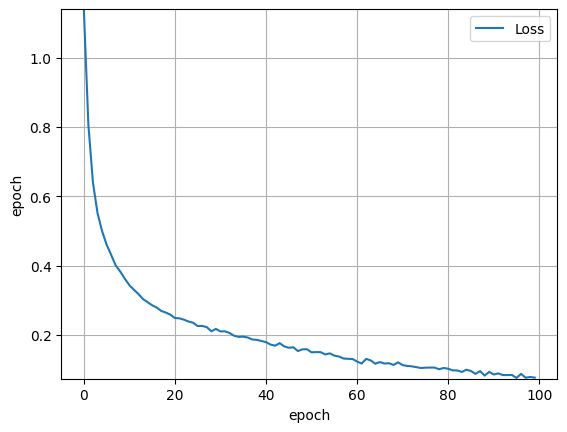

In [11]:
training_size = 200
base_range = np.random.default_rng()
tr_features_x = -10 + 20*base_range.random(size = training_size)
tr_features_y = -10 + 20*base_range.random(size = training_size)
tr_classes = [to_categorical(x,y) for x,y in zip(tr_features_x, tr_features_y)]

tr_labels = tf.keras.utils.to_categorical(tr_classes, num_classes=4)

def build_model(rate):
    # Строим модель в виде последовательно подключаемых
    # слоев (промежуточные слои соединяются автоматом).
    model = tf.keras.models.Sequential()

    model.add(tf.keras.layers.Dense(units=32, input_shape=(2,), activation='relu'))
    model.add(tf.keras.layers.Dense(units=16, activation='relu'))
    model.add(tf.keras.layers.Dense(units=16, activation='relu'))
    model.add(tf.keras.layers.Dense(units=16, activation='relu'))
    model.add(tf.keras.layers.Dense(units=4, activation='softmax'))

    # Скомпилируем нашу модель в код, который исполнит
    # TensorFlow. В качестве функции потерь, которую
    # мы будем минимизировать, выберем среднеквадратическую ошибку
    loss = tf.keras.losses.CategoricalCrossentropy()
    model.compile(optimizer = tf.keras.optimizers.RMSprop(learning_rate = rate), loss = loss, metrics = [tf.keras.metrics.RootMeanSquaredError()])
    return model

#функция для обучения модели на эталонных данных
def train_model(model, feature, label, epochs, batch_size):
    history = model.fit(x = feature, y = label, batch_size = batch_size, epochs = epochs)
    #trained_weight = model.get_weights()[0]
    #trained_bias = model.get_weights()[1]
    epochs = history.epoch
    hist = pd.DataFrame(history.history)
    loss = hist["loss"]
    return epochs, loss


tr_features = np.array([tr_features_x, tr_features_y]).T
#print(len(tr_features))
#print(len(tr_labels))

learn_rate = 0.001
n_epochs = 100
my_model = build_model(learn_rate)
my_batch_size = 10
epochs, rmse = train_model(model = my_model,
                            feature = tr_features,
                            label = tr_labels,
                            epochs = n_epochs,
                            batch_size = my_batch_size)
Rmse = np.array([rmse[i] for i in range(100)])
plot_the_loss_curve(epochs, Rmse)


3125/3125 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


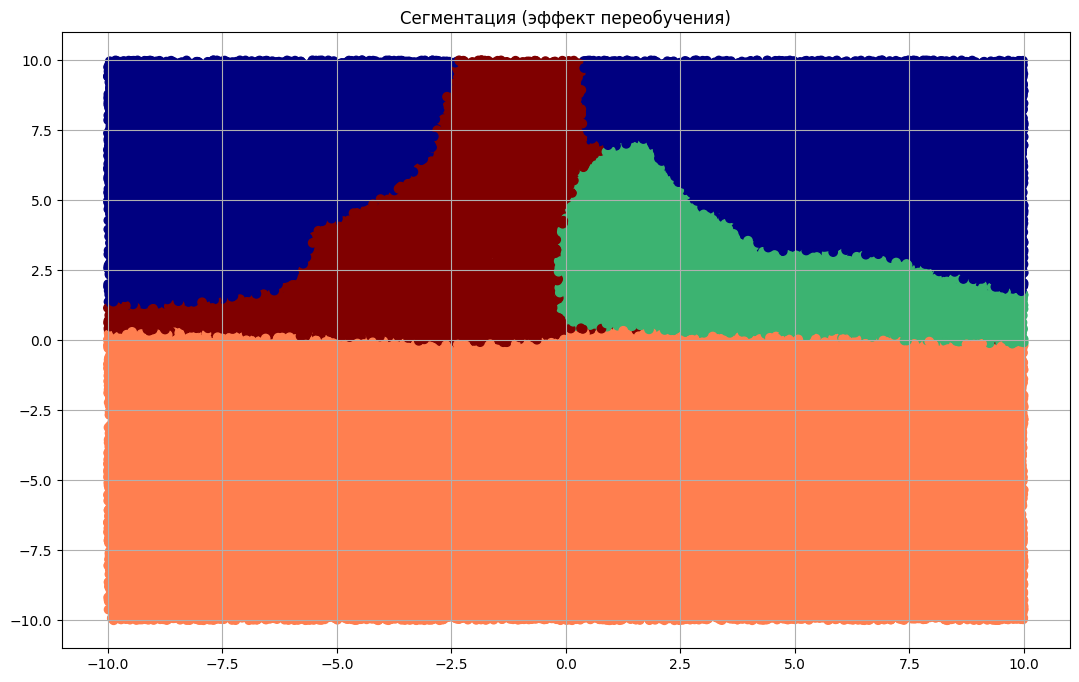

In [12]:
size = 100000
base_range = np.random.default_rng()
features_x = -10 + 20*base_range.random(size = size)
features_y = -10 + 20*base_range.random(size = size)
features = np.array([features_x, features_y]).T
classes = [to_categorical(x,y) for x,y in zip(features_x, features_y)]
labels = tf.keras.utils.to_categorical(classes, num_classes=None)
predictions = np.round(my_model.predict(features))
predicted_classes = [prediction for prediction in np.argmax(predictions, -1)]

colors = ['maroon', 'mediumseagreen', 'navy', 'coral', 'gold']
fig = plt.figure(figsize = (10, 7))
fig.set_size_inches((13, 8))
ax = fig.add_subplot()
ax.set_title('Сегментация (эффект переобучения)')
ax.grid(True)
ax.scatter(features_x, features_y, c=[colors[class_id] for class_id in predicted_classes])